# Group Project Cryosphere

Earth Observation group project about a glacier in the Himalaya in Nepal. We try to measure glacier area, surface temperature variation, and wet/total snow area using satellite data from Google Earth Engine. We investigate these aspects on the time series of 2015 - 2026.

## Initializing

In [73]:
import time
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
from plotting import *
from gst_series import *

In [2]:
# run once at beginning, supply token
import ee
ee.Authenticate()

True

In [3]:
GEE_PROJECT = "my-hello-world-508910"  # replace with your own project id
ee.Initialize(project=GEE_PROJECT)

In [4]:
ROI = [[81.757507, 30.201033], [81.756821, 30.220912], [81.759224, 30.242269], [81.764717, 30.255022], [81.779823, 30.248794], [81.789093, 30.230701], [81.79184, 30.20222], [81.78669, 30.187383], [81.766777, 30.184416], [81.757507, 30.201033]]
AOI = ee.Geometry.Polygon(ROI) # from WhatsApp chat
aoi_center_lon_lat = AOI.centroid().coordinates().getInfo() # lon/lat
print(aoi_center_lon_lat)

[81.77351981643862, 30.21758428472221]


In [5]:
START = "2015-01-01"
END = "2026-12-31"

## Image Collections Analysis

Get a sense of how many Images we are working with, from what date they are and how much they are covered by clouds.

In [6]:
s2_toa = ee.ImageCollection("COPERNICUS/S2_HARMONIZED").filterBounds(AOI).sort("system:time_start").set("collection_name", "Sentinel 2 Top of Atmosphere")
s2_boa = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(AOI).sort("system:time_start").set("collection_name", "Sentinel 2 Bottom of Atmosphere")

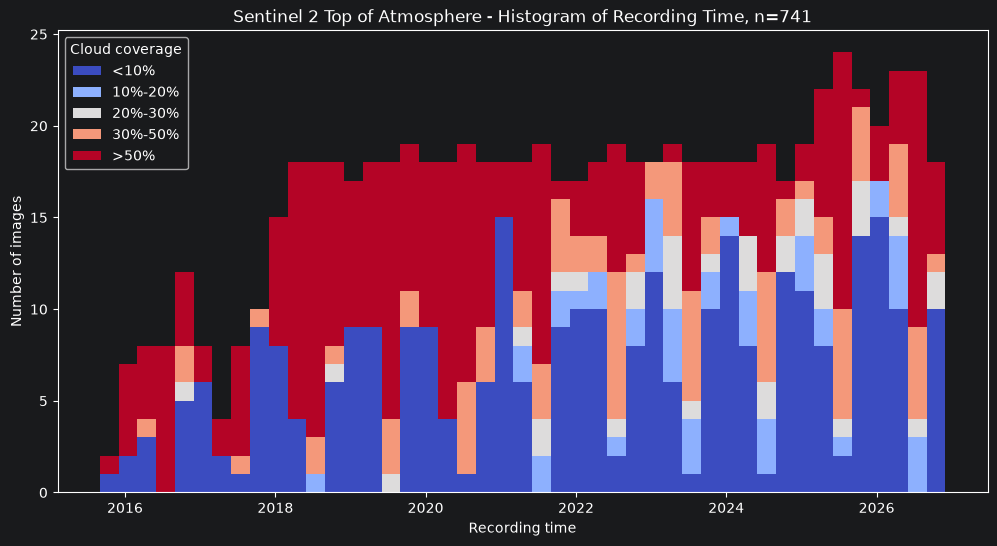

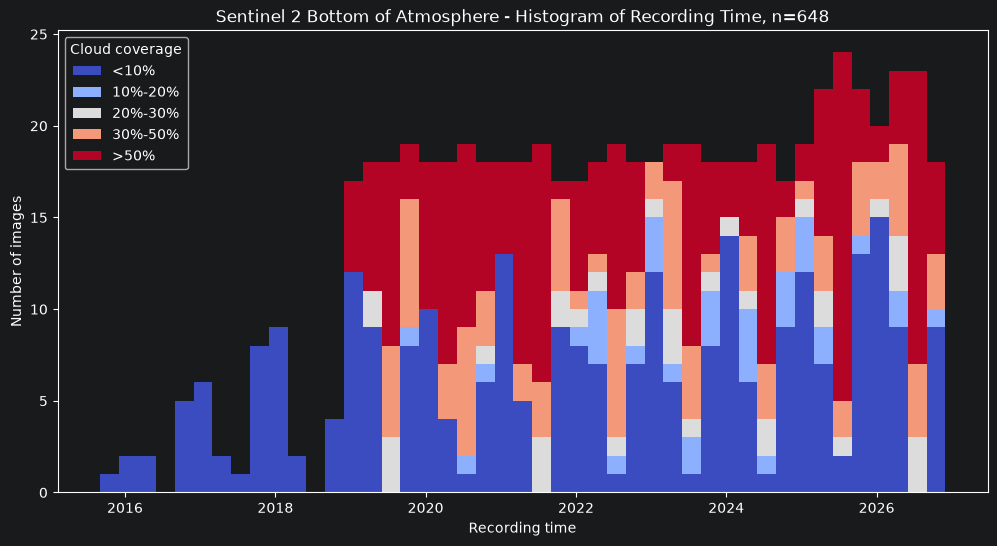

In [7]:
plot_histogram_image_collection(s2_toa, "2015-09-01", "2027-01-01")
plot_histogram_image_collection(s2_boa, "2015-09-01", "2027-01-01")

In these Histograms we see that there Sentinel 2 provides data with few clouds from 2016 to 2026. Also, we see that cloud cover is very seasonal. Especially in summer, images with cloud coverage <30% are scarce. Although more and more images are provided throughout the time period, image count has been very consistent since 2019.

## Glacier area

Description here...

## Surface temperature variation

Description here...

In [8]:
glacier_mask, mask_status = get_glacier_mask(roi=AOI)
print("Glacier mask source:", mask_status)

Glacier mask source: GLIMS/current outlines


In [9]:
dem = ee.Image("USGS/SRTMGL1_003").select("elevation")
bin_img = dem.divide(BIN_M).floor().multiply(BIN_M).toInt().rename("bin") # 50 bzw. BIN_M grosse Höhenstufen
show_map(dem=dem, roi=AOI, glacier_mask=glacier_mask)

Map(center=[30.21758428472345, 81.77351981643268], controls=(WidgetControl(options=['position', 'transparent_b…

In [10]:
raw_gst = download(bin_img, glacier_mask, AOI, START, END, debug=False)
gst_half_month = process(raw_gst, debug=True)
ablation_trend = ablation_trend(gst_half_month, debug=True)
gst_half_month.head()

2015 scenes x bins: 399
2016 scenes x bins: 399
2017 scenes x bins: 437
2018 scenes x bins: 418
2019 scenes x bins: 437
2020 scenes x bins: 418
2021 scenes x bins: 494
2022 scenes x bins: 817
2023 scenes x bins: 836
2024 scenes x bins: 855
2025 scenes x bins: 836
2026 scenes x bins: 703

Elevation zones (m a.s.l.):
  zone1 (low): 5250-5450 m, area share 0.32
  zone2: 5450-5600 m, area share 0.36
  zone3 (high): 5600-6200 m, area share 0.32

Ablation-season (Jun-Sep) GST trend, deg C per decade:
  zone1 (low): too few years (1)


,date,year,hm,zone,gst,gst_sd,gst_unc
0,2015-01-08,2015,0,whole glacier,-14.923550,3.307724,4.448690
1,2015-02-08,2015,2,whole glacier,-12.752938,0.876773,4.484846
2,2015-03-23,2015,5,whole glacier,-12.664821,0.802712,4.578796
3,2015-04-23,2015,7,whole glacier,-3.338926,1.811285,4.415173
4,2015-05-08,2015,8,whole glacier,-3.443233,2.057313,4.562039


In [74]:
plot_half_months(gst_half_month)

NameError: name 'plot_half_months' is not defined

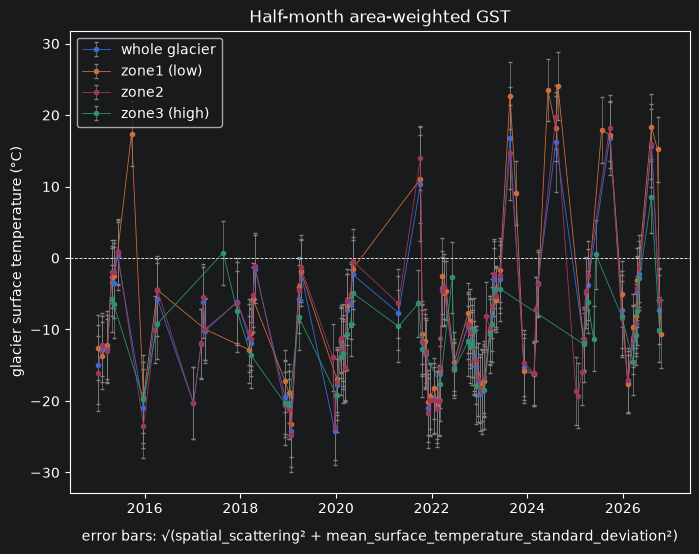

In [11]:
fig_err = plot_gst_series(gst_half_month, errorbars=True)
fig_noerr = plot_gst_series(gst_half_month, errorbars=False)

## Wet/total snow area

Description here...